# Task 3 — Predictive Customer Churn Classifier (Random Forest & XGBoost)

**Goal:** Predict which telecom customers will churn, handle the **class imbalance**, and optimise **ROC-AUC** (target > 0.80).

**Pipeline:**
1. Load Telco Customer Churn data and clean it (`TotalCharges` → numeric, handle nulls)
2. EDA: churn rate and the strongest drivers
3. Preprocess: `OneHotEncoder` for categoricals (inside a Pipeline, so nothing leaks from the test set)
4. Balance classes with **SMOTE** *or* **class weighting**, and compare both
5. Train **Random Forest** and **XGBoost** with 5-fold stratified cross-validation + `GridSearchCV`
6. Evaluate: ROC-AUC curves, confusion matrix, precision / recall / F1
7. Top 10 feature importances and business takeaways

In [1]:
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline   # applies SMOTE only to training folds

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. Load and clean the data

In [2]:
LOCAL = "telco.csv"
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
# TotalCharges is stored as text because 11 rows contain blank strings
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nNulls after converting TotalCharges to numeric:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nThose rows all have tenure == 0 (brand-new customers):", (df.loc[df.TotalCharges.isna(), "tenure"] == 0).all())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# New customers with tenure 0 have not been billed yet, so TotalCharges = 0 is the logical fill
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns=["customerID"])               # identifier, no predictive value
df["Churn"] = (df["Churn"] == "Yes").astype(int)   # target: 1 = churned
print("Duplicates:", df.duplicated().sum())
df.describe(include="all").T.head(8)

Duplicates: 22


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Exploratory analysis — the class imbalance problem

Churn rate: 26.5%  ->  imbalance ratio about 2.8 : 1


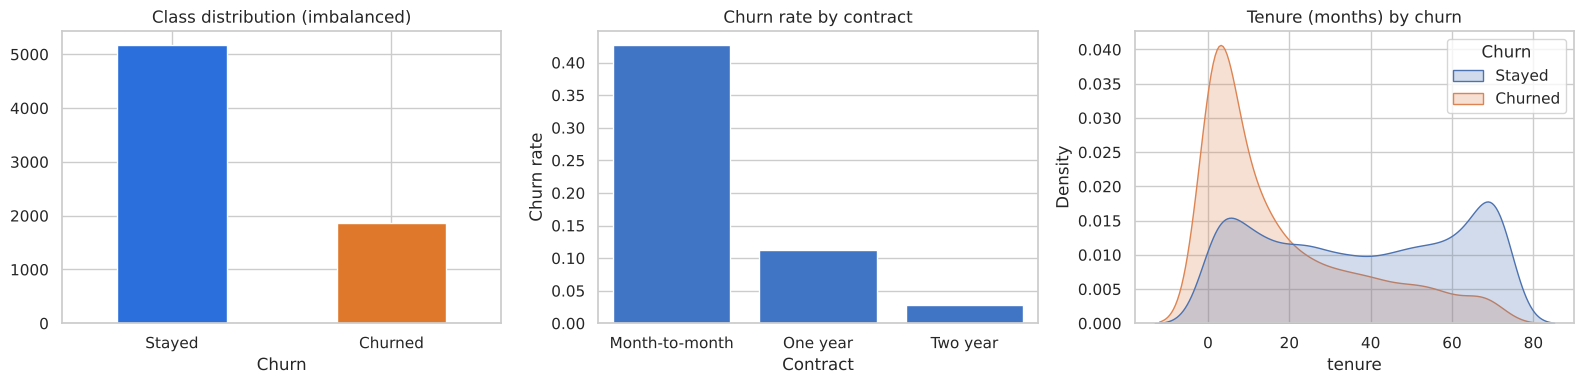

In [5]:
rate = df["Churn"].mean()
print(f"Churn rate: {rate:.1%}  ->  imbalance ratio about {(1-rate)/rate:.1f} : 1")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(ax=axes[0], color=["#2a6fdb", "#e0782b"], rot=0)
axes[0].set_title("Class distribution (imbalanced)")
sns.barplot(data=df, x="Contract", y="Churn", ax=axes[1], color="#2a6fdb", errorbar=None)
axes[1].set_title("Churn rate by contract"); axes[1].set_ylabel("Churn rate")
sns.kdeplot(data=df, x="tenure", hue=df["Churn"].map({0: "Stayed", 1: "Churned"}), fill=True, common_norm=False, ax=axes[2])
axes[2].set_title("Tenure (months) by churn")
plt.tight_layout(); plt.show()

**Observation:** only about 1 in 4 customers churn, so plain accuracy is misleading (a model that always says *'stays'* would be about 73% accurate). This is why we optimise **ROC-AUC** and watch **recall** on the churn class. Month-to-month contracts and low tenure show the highest churn.

## 3. Train / test split and preprocessing

In [6]:
X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()
print("\nCategorical:", len(cat_cols), "| Numeric:", num_cols)

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight for XGBoost = {pos_weight:.2f}")

Train: (5634, 19) | Test: (1409, 19)
Churn rate train / test: 0.265 / 0.265

Categorical: 15 | Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
scale_pos_weight for XGBoost = 2.77


## 4. Models — four setups compared

| Setup | Imbalance handling |
|---|---|
| Random Forest + SMOTE | synthetic minority samples (inside each CV training fold only) |
| Random Forest + class weights | `class_weight="balanced"` |
| XGBoost + SMOTE | synthetic minority samples |
| XGBoost + class weights | `scale_pos_weight` |

Each one is tuned with `GridSearchCV` (5-fold stratified, scoring = **ROC-AUC**). Putting SMOTE *inside* an `imblearn` Pipeline means the validation folds are never oversampled, so the CV score is honest.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def build(model, use_smote):
    steps = [("prep", preprocess)]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return ImbPipeline(steps)

rf_grid  = {"model__n_estimators": [200, 400], "model__max_depth": [8, 14], "model__min_samples_leaf": [2, 5]}
xgb_grid = {"model__n_estimators": [200, 400], "model__max_depth": [3, 5], "model__learning_rate": [0.03, 0.1]}

setups = {
    "RF + SMOTE":         (build(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), True),  rf_grid),
    "RF + class weight":  (build(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1), False), rf_grid),
    "XGB + SMOTE":        (build(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1), True), xgb_grid),
    "XGB + class weight": (build(XGBClassifier(scale_pos_weight=pos_weight, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1), False), xgb_grid),
}

fitted = {}
for name, (pipe, grid) in setups.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=1, refit=True).fit(X_train, y_train)
    fitted[name] = gs
    print(f"{name:20s} CV ROC-AUC = {gs.best_score_:.4f}  ({time.time()-t0:.0f}s)  best = { {k.split('__')[1]: v for k, v in gs.best_params_.items()} }")

RF + SMOTE           CV ROC-AUC = 0.8420  (55s)  best = {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 400}


RF + class weight    CV ROC-AUC = 0.8476  (46s)  best = {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 400}


XGB + SMOTE          CV ROC-AUC = 0.8475  (25s)  best = {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 400}


XGB + class weight   CV ROC-AUC = 0.8480  (9s)  best = {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}


## 5. Evaluation on the held-out test set

In [8]:
rows = []
for name, gs in fitted.items():
    proba = gs.predict_proba(X_test)[:, 1]
    pred  = (proba >= 0.5).astype(int)
    rows.append({"model": name, "CV ROC-AUC": gs.best_score_, "Test ROC-AUC": roc_auc_score(y_test, proba),
                 "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
results = pd.DataFrame(rows).set_index("model").round(4)
display(results)
best_name = results["Test ROC-AUC"].idxmax()
print(f"Best model by test ROC-AUC: {best_name}  ({results.loc[best_name, 'Test ROC-AUC']:.4f}) -> target > 0.80 reached: {results.loc[best_name, 'Test ROC-AUC'] > 0.80}")

,CV ROC-AUC,Test ROC-AUC,Accuracy,Precision,Recall,F1
model,,,,,,
RF + SMOTE,0.8420,0.8348,0.7736,0.5647,0.6417,0.6008
RF + class weight,0.8476,0.8424,0.7488,0.5174,0.7968,0.6274
XGB + SMOTE,0.8475,0.8455,0.7885,0.6073,0.5749,0.5907
XGB + class weight,0.8480,0.8457,0.7480,0.5162,0.8102,0.6306


Best model by test ROC-AUC: XGB + class weight  (0.8457) -> target > 0.80 reached: True


### ROC curves

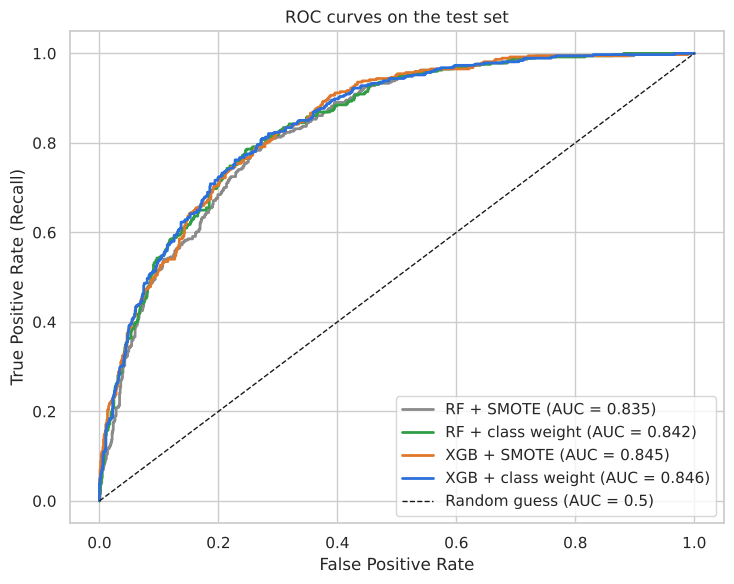

In [9]:
colors = {"RF + SMOTE": "#8a8a8a", "RF + class weight": "#2f9e44", "XGB + SMOTE": "#e0782b", "XGB + class weight": "#2a6fdb"}
plt.figure(figsize=(7.5, 6))
for name, gs in fitted.items():
    proba = gs.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, color=colors[name], label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (AUC = 0.5)")
plt.axhline(0, color="none")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### Confusion matrices

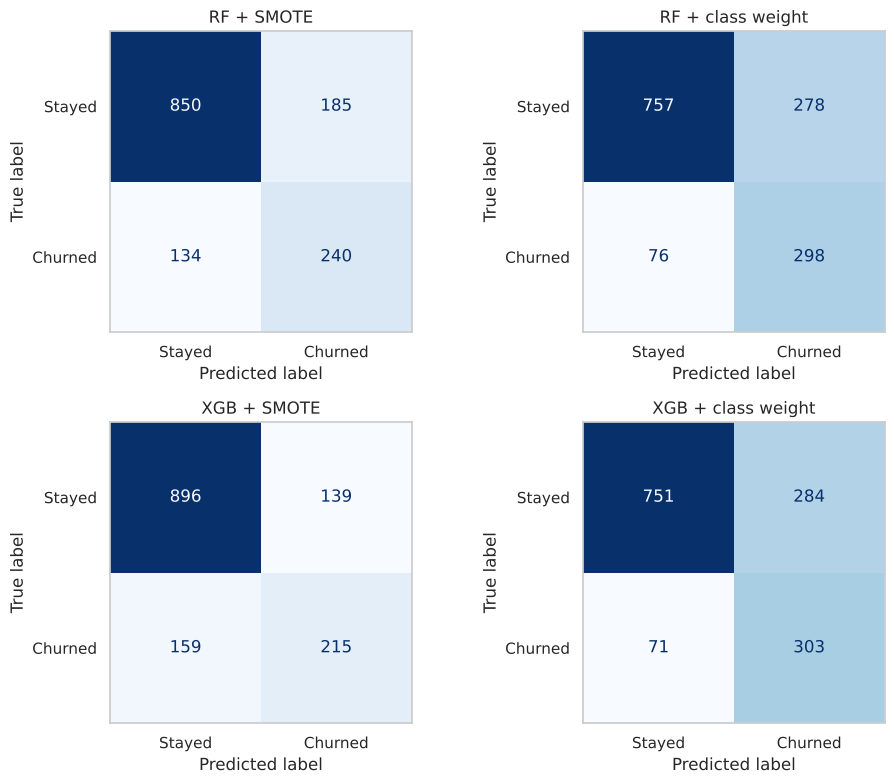

Detailed report for the best model: XGB + class weight
              precision    recall  f1-score   support

      Stayed       0.91      0.73      0.81      1035
     Churned       0.52      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, gs) in zip(axes.ravel(), fitted.items()):
    pred = gs.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Churned"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.show()

print(f"Detailed report for the best model: {best_name}")
print(classification_report(y_test, fitted[best_name].predict(X_test), target_names=["Stayed", "Churned"]))

### Choosing the decision threshold
The default threshold of 0.5 is not necessarily right for churn. Missing a churner (false negative) usually costs more than sending a retention offer to someone who would have stayed (false positive). The threshold below is picked using **cross-validated predictions on the training set only**, so the test set stays untouched.

F1-optimal threshold (from training CV): 0.57


,threshold,precision,recall,F1
0,0.50,0.516,0.810,0.631
1,0.57,0.548,0.743,0.631


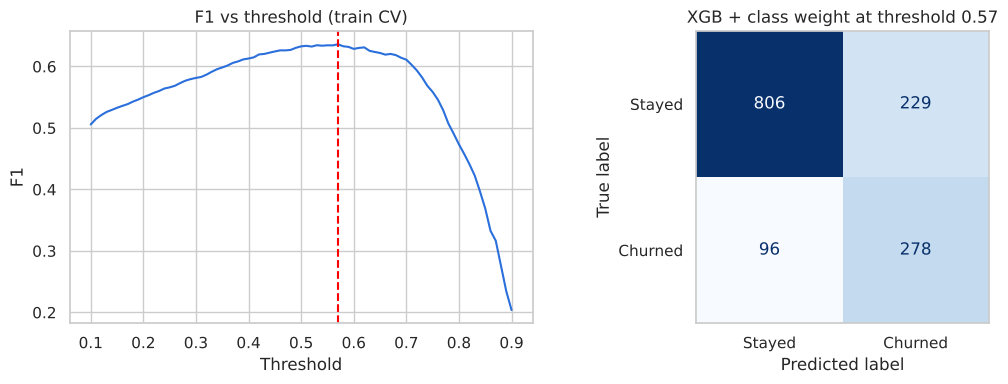

In [11]:
best = fitted[best_name].best_estimator_
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.linspace(0.1, 0.9, 81)
f1s = [f1_score(y_train, (oof >= t).astype(int)) for t in thresholds]
t_best = thresholds[int(np.argmax(f1s))]
print(f"F1-optimal threshold (from training CV): {t_best:.2f}")

proba_test = fitted[best_name].predict_proba(X_test)[:, 1]
cmp = pd.DataFrame({
    "threshold": [0.5, t_best],
    "precision": [precision_score(y_test, proba_test >= t) for t in (0.5, t_best)],
    "recall":    [recall_score(y_test, proba_test >= t) for t in (0.5, t_best)],
    "F1":        [f1_score(y_test, proba_test >= t) for t in (0.5, t_best)],
}).round(3)
display(cmp)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(thresholds, f1s, color="#2a6fdb"); axes[0].axvline(t_best, color="red", ls="--")
axes[0].set(title="F1 vs threshold (train CV)", xlabel="Threshold", ylabel="F1")
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= t_best).astype(int), display_labels=["Stayed", "Churned"],
                                        cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title(f"{best_name} at threshold {t_best:.2f}"); axes[1].grid(False)
plt.tight_layout(); plt.show()

## 6. Feature importance — what drives churn?

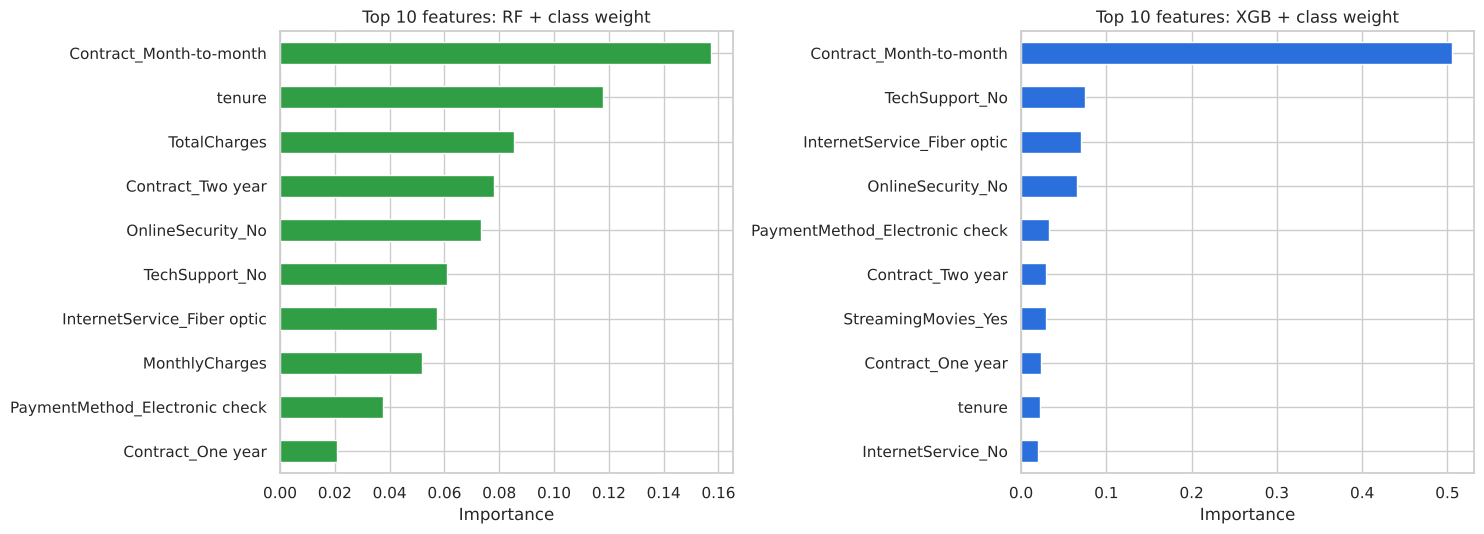

In [12]:
def top_importances(gs, n=10):
    pipe = gs.best_estimator_
    names = pipe.named_steps["prep"].get_feature_names_out()
    names = [x.split("__", 1)[1] for x in names]
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
    return imp.sort_values(ascending=False).head(n)[::-1]

rf_name  = results.loc[[n for n in results.index if n.startswith("RF")], "Test ROC-AUC"].idxmax()
xgb_name = results.loc[[n for n in results.index if n.startswith("XGB")], "Test ROC-AUC"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
top_importances(fitted[rf_name]).plot.barh(ax=axes[0], color="#2f9e44");  axes[0].set_title(f"Top 10 features: {rf_name}")
top_importances(fitted[xgb_name]).plot.barh(ax=axes[1], color="#2a6fdb"); axes[1].set_title(f"Top 10 features: {xgb_name}")
for ax in axes: ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

## 7. Conclusion

| Aspect | Result |
|---|---|
| Target | ROC-AUC > 0.80 **reached by all four setups** (test AUC 0.835 to 0.846; 5-fold CV AUC 0.842 to 0.848) |
| Best model | **XGBoost + class weighting** (`scale_pos_weight`): test ROC-AUC 0.846, recall 0.81 on churners, F1 0.63 |
| SMOTE vs class weights | AUC is almost identical. SMOTE gave higher precision and accuracy but missed more churners (recall about 0.57 to 0.64). Class weighting caught about 80% of churners, so it fits a retention use case better |
| RF vs XGBoost | XGBoost is slightly better and much faster to train; Random Forest is close behind |
| Threshold | The F1-optimal threshold (0.57, chosen on train CV only) trades recall for precision with the same F1, so the choice depends on the cost of a missed churner vs a wasted retention offer |

**What drives churn (top features):**
- **Month-to-month contracts** are by far the strongest signal; two-year contracts protect against churn.
- **Short tenure** and low total charges (new customers) churn more.
- **Fiber optic** internet and **no online security / no tech support** are linked to higher churn.
- **Electronic check** payment is also associated with churn.

**Business takeaway:** target new month-to-month, fiber-optic customers without support add-ons with retention offers (for example a discount for moving to a yearly contract, or bundled tech support).

**Limitations / next steps:** AUC is similar across all models, which suggests the features (not the algorithm) are the ceiling. Possible improvements: feature engineering (e.g. number of add-on services), a wider hyperparameter search (`RandomizedSearchCV`), probability calibration, and SHAP values for per-customer explanations.